# Mori–Zwanzig meets Equivariant Graph Neural Networks
## AI INFN Hackathon@Ferrara · 2 December 2026
**Alessandro Gabbana** ([alessandro.gabbana@unife.it](mailto:alessandro.gabbana@unife.it)) · **André Freitas** ([Andre.Freitas@roma2.infn.it](mailto:Andre.Freitas@roma2.infn.it))

In notebooks 01–02 we learned **memory** (Mori–Zwanzig operators) for low-dimensional systems. <br>
In notebook 03 we learned **symmetries** (equivariant GNNs) for interacting particles.  <br>
Here we try to put all the ingredients together:

$$
\mathbf{a}_i^{\,n} \;=\; \sum_{k=0}^{K} \boldsymbol{\Omega}^{(k)}_\theta\bigl(\mathcal{G}^{\,n-ks},\, \mathbf{v}^{\,n-ks}\bigr)_i ,
\qquad \text{each } \boldsymbol{\Omega}^{(k)}_\theta \text{ an equivariant GNN.}
$$

We study two simple 2D particle systems in which we **observe only some degrees of freedom**:

| | Part A: colloids + hidden beads | Part B: heavy colloids in a bath |
|---|---|---|
| resolved | 20 colloids | 6 heavy colloids |
| unresolved | one relaxing bead per colloid | 100 light bath particles |
| memory kernel | **known analytically** (exponential) | unknown |

In [ ]:
import math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

def pick_device():
    # torch.cuda.is_available() can be True on GPUs too old for the installed build: test it
    if torch.cuda.is_available():
        try:
            torch.zeros(1, device="cuda") + 1
            return torch.device("cuda")
        except Exception:
            pass
    return torch.device("cpu")

dev = pick_device()

torch.manual_seed(0)
np.random.seed(0)

print("device:", dev)

device: cpu


/opt/miniconda3/lib/python3.13/site-packages/torch/cuda/__init__.py:371: UserWarning: Found GPU0 Quadro P520 which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0 except {8.7}
- 8.6 which supports hardware CC >=8.6,<9.0 except {8.7}
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Please follow the instructions at https://pytorch.org/get-started/locally/ to install a PyTorch release that supports one of these CUDA versions: 12.6
  _warn_unsupported_code(d, device_cc, code_ccs)
/opt/miniconda3/lib/python3.13/site-packages/torch/cuda/__init__.py:489: UserWarning: 
Quadro P520 with CUDA capability sm_61 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilit

## 0. Shared tools

Both systems live in a periodic square box of side $L$. All pair vectors use the **minimum-image convention**,
both in the simulator and in the graph neural network, so physics and model see the same neighbours.

Particles interact through a soft harmonic repulsion: two particles with diameters $\sigma_i, \sigma_j$ at distance
$d_{ij} < \sigma_{ij} = (\sigma_i + \sigma_j)/2$ push each other apart with force $k_{\rm rep}(\sigma_{ij} - d_{ij})$.

In [2]:
def min_image(d, L):
    return d - L * torch.round(d / L)

def pair_vectors(x, L):
    # r[b, i, j] = x_j - x_i  (minimum image);  x: (B, N, 2)
    return min_image(x[:, None, :, :] - x[:, :, None, :], L)

def repulsion(x, L, sigma, k_rep):
    r = pair_vectors(x, L)
    d = r.norm(dim=-1)
    sij = 0.5 * (sigma[:, None] + sigma[None, :])
    eye = torch.eye(x.shape[1], dtype=torch.bool, device=x.device)
    overlap = torch.relu(sij - d).masked_fill(eye, 0.0)
    return -(k_rep * overlap / d.masked_fill(eye, 1.0))[..., None].mul(r).sum(2)

def init_positions(B, N, L, sigma, k_rep):
    x = torch.rand(B, N, 2, device=dev) * L
    for _ in range(2000):  # overdamped relaxation removes overlaps
        x = (x + 1e-3 * repulsion(x, L, sigma, k_rep)) % L
    return x

def vacf(V, maxlag):
    # velocity autocorrelation <v(t0+t).v(t0)> / <|v|^2>, averaged over systems, particles, t0;  V: (B, T, N, 2)
    c = [(V[:, lag:] * V[:, :V.shape[1] - lag]).sum(-1).mean().item() for lag in range(maxlag)]
    return np.array(c) / c[0]

---
# Part A: colloids with a hidden bead

## A1. The system

Each colloid $i$ (mass $M$) is tied by a spring $k_b$ to a hidden bead $\mathbf{b}_i$, which relaxes towards its colloid
at rate $\lambda$ and is kicked by thermal noise:

$$
M\ddot{\mathbf{x}}_i = \mathbf{F}^{\rm rep}_i + k_b(\mathbf{b}_i - \mathbf{x}_i),
\qquad
\dot{\mathbf{b}}_i = -\lambda(\mathbf{b}_i - \mathbf{x}_i) + \sqrt{2D}\,\boldsymbol{\xi}_i(t).
$$

**We observe only the colloids.** The beads are the unresolved variables $\mathbf{y}$.

### Eliminating the bead exactly
With $\mathbf{u}_i = \mathbf{b}_i - \mathbf{x}_i$ we get $\dot{\mathbf{u}}_i = -\lambda \mathbf{u}_i - \mathbf{v}_i + \sqrt{2D}\boldsymbol{\xi}_i$, a linear equation we can solve:

$$
M\ddot{\mathbf{x}}_i
= \underbrace{\mathbf{F}^{\rm rep}_i(t)}_{\text{Markovian}}
\;-\; \underbrace{\int_0^t k_b\, e^{-\lambda(t-s)}\, \mathbf{v}_i(s)\, ds}_{\text{memory}}
\;+\; \underbrace{k_b\Bigl[e^{-\lambda t}\mathbf{u}_i(0) + \int_0^t e^{-\lambda(t-s)}\sqrt{2D}\,\boldsymbol{\xi}_i(s)\,ds\Bigr]}_{\text{orthogonal dynamics } \mathbf{F}_i(t)}
$$

- **memory kernel** $K(\tau) = k_b e^{-\lambda \tau}$: we will compare the learned operators with it;
- **orthogonal dynamics** with correlation $\langle \mathbf{F}(t)\cdot\mathbf{F}(t')\rangle \propto e^{-\lambda|t-t'|}$;
- choosing $D = \lambda k_B T / k_b$ gives $\langle F_\alpha(t) F_\alpha(t')\rangle = k_B T\, K(t-t')$: from the **fluctuation–dissipation theorem** the colloids sit at temperature $T$.

### Symmetries
Permutation, translation, rotation: yes. **Galilean invariance: no.** The medium is at rest, so a uniformly moving colloid feels drag.
Our GNN must therefore be allowed to use the absolute velocity $\mathbf{v}_i$, not only relative velocities.

In [ ]:
A = dict(N=20, L=6.0, sigma=1.0, 
         k_rep=50.0, M=1.0, k_b=5.0, 
         lam=2.0, T=1.0,
         dt_sim=2e-3, sub=10)          # simulation step 2e-3, we store every 10 steps
dtA = A["dt_sim"] * A["sub"]           # sampling step of the data = model step = 0.02

def simulate_beads(B, n_samples, p=A, burn=2000):
    N, L = p["N"], p["L"]
    sig = torch.full((N,), p["sigma"], device=dev)
    D = p["lam"] * p["T"] / p["k_b"] 
    x = init_positions(B, N, L, sig, p["k_rep"])
    v = torch.randn(B, N, 2, device=dev) * math.sqrt(p["T"] / p["M"])
    b = x + torch.randn_like(x) * math.sqrt(p["T"] / p["k_b"])
    dt = p["dt_sim"]
    X, V, Bd = [], [], []
    for s in range(burn + n_samples * p["sub"]):
        F = repulsion(x, L, sig, p["k_rep"]) + p["k_b"] * min_image(b - x, L)
        v = v + dt * F / p["M"]
        x_new = x + dt * v
        b = b + dt * p["lam"] * min_image(x - b, L) + math.sqrt(2 * D * dt) * torch.randn_like(b)
        x = x_new % L
        if s >= burn and (s - burn) % p["sub"] == 0:
            X.append(x.clone()); V.append(v.clone()); Bd.append(b.clone())
    return torch.stack(X, 1).cpu(), torch.stack(V, 1).cpu(), torch.stack(Bd, 1).cpu()   # (B, T, N, 2)

t0 = time.time()
XA, VA, BA = simulate_beads(B=16, n_samples=2000)

print(f"simulated {XA.shape} in {time.time() - t0:.0f}s;  kinetic temperature = {A['M'] * VA.pow(2).mean():.3f} (target {A['T']})")

simulated torch.Size([16, 2000, 20, 2]) in 16s;  kinetic temperature = 1.003 (target 1.0)


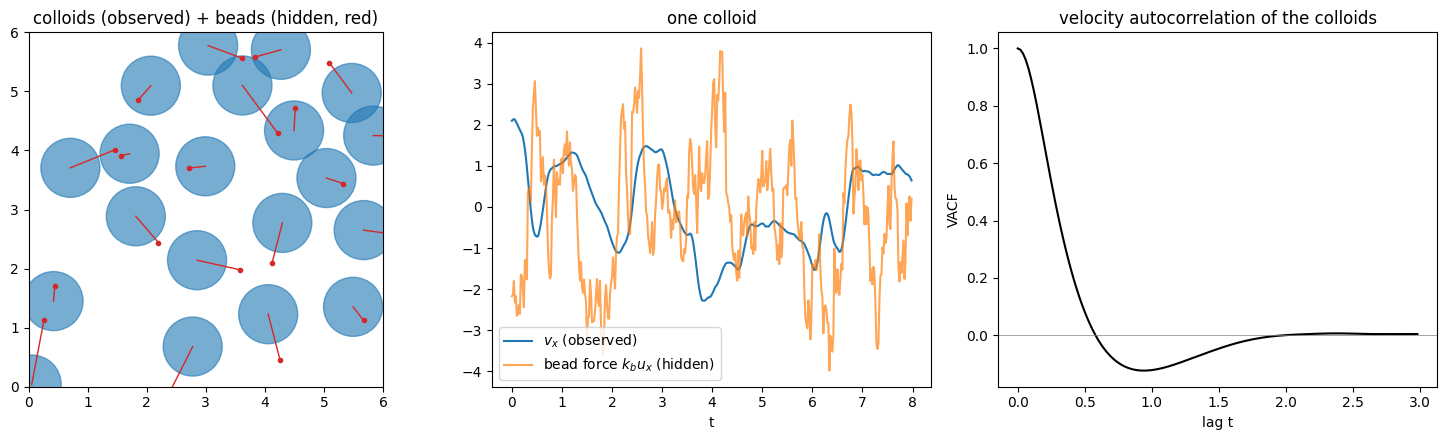

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
x0, b0 = XA[0, 0], BA[0, 0]
for i in range(A["N"]):
    ax[0].add_patch(plt.Circle(x0[i], A["sigma"] / 2, color="C0", alpha=0.6))
    db = min_image(b0[i] - x0[i], A["L"])
    ax[0].plot([x0[i, 0], x0[i, 0] + db[0]], [x0[i, 1], x0[i, 1] + db[1]], "C3-", lw=1)
    ax[0].plot(x0[i, 0] + db[0], x0[i, 1] + db[1], "C3o", ms=3)
ax[0].set(xlim=(0, A["L"]), ylim=(0, A["L"]), aspect="equal", title="colloids (observed) + beads (hidden, red)")

t = np.arange(400) * dtA
ax[1].plot(t, VA[0, :400, 0, 0], label="$v_x$ (observed)")
ax[1].plot(t, A["k_b"] * min_image(BA[0, :400, 0, 0] - XA[0, :400, 0, 0], A["L"]), label="bead force $k_b u_x$ (hidden)", alpha=0.7)
ax[1].set(xlabel="t", title="one colloid"); ax[1].legend()

lags = np.arange(150) * dtA
ax[2].plot(lags, vacf(VA, 150), "k")
ax[2].axhline(0, color="gray", lw=0.5)
ax[2].set(xlabel="lag t", ylabel="VACF", title="velocity autocorrelation of the colloids")
plt.tight_layout(); plt.show()

The **negative dip** in the velocity autocorrelation is a fingerprint of memory: the stretched spring pulls the colloid back towards where it came from. <br>
A Markovian model with plain friction, $\dot{v} = -\gamma v + \text{noise}$, can only give a monotonic exponential decay.

## A2. The model: an E(2)-equivariant GNN

We introduce two practical choices:

- **sparse graph in plain PyTorch**: edges $j \to i$ whenever $|\mathbf{r}_{ij}| < r_c$ (minimum image).
- **vector-only message passing**: node features are vectors $\mathbf{h}_i$ (starting from $\mathbf{0}$), and every vector is built as *invariant scalar × vector*:

$$
\mathbf{m}_{ij} = \alpha\,\mathbf{r}_{ij} + \beta\,\mathbf{v}_{ij} + \gamma\,\mathbf{h}_{ij},
\qquad (\alpha,\beta,\gamma) = \phi_e\bigl(|\mathbf{r}_{ij}|^2, \mathbf{r}_{ij}\!\cdot\!\mathbf{v}_{ij}, |\mathbf{v}_{ij}|^2, \mathbf{r}_{ij}\!\cdot\!\mathbf{h}_{ij}, \mathbf{v}_{ij}\!\cdot\!\mathbf{h}_{ij}, |\mathbf{h}_{ij}|^2\bigr)
$$
$$
\mathbf{h}_i \leftarrow \mathbf{h}_i + \tfrac{1}{c}\sum_{j} \mathbf{m}_{ij} \;+\; a\,\mathbf{v}_i + b\,\mathbf{h}_i,
\qquad (a, b) = \phi_n\bigl(|\mathbf{v}_i|^2, \mathbf{v}_i\!\cdot\!\mathbf{h}_i, |\mathbf{h}_i|^2\bigr)
$$

The **self term** $a\,\mathbf{v}_i$ is what lets the model feel the medium at rest (drag). It keeps rotation equivariance but, on purpose, breaks Galilean invariance. <br> 
We use a sum over neighbours (not a mean): forces add up. After the last layer, $\mathbf{h}_i$ is the output acceleration.

The **MZ-EGNN** is a sum of $K+1$ such networks, each one looking at the graph at a different delay $k s$ (stride $s$).

In [5]:
def mlp(i, h, o, n=2):
    layers, d = [], i
    for _ in range(n):
        layers += [nn.Linear(d, h), nn.SiLU()]; d = h
    return nn.Sequential(*layers, nn.Linear(d, o))

def radius_graph_pbc(x, L, rc):
    # edges i <- j with |x_j - x_i| < rc; nodes of all systems in the batch are flattened to B*N
    B, N, _ = x.shape
    r = pair_vectors(x, L)
    mask = (r.norm(dim=-1) < rc) & ~torch.eye(N, dtype=torch.bool, device=x.device)
    b, i, j = mask.nonzero(as_tuple=True)
    return b * N + i, b * N + j, r[b, i, j]

class EGNNLayer(nn.Module):
    def __init__(self, hidden=32, norm=4.0):
        super().__init__()
        self.edge, self.node, self.norm = mlp(6, hidden, 3), mlp(3, hidden, 2), norm

    def forward(self, i, j, r, v, h):
        dot = lambda a, b: (a * b).sum(-1)
        vij, hij = v[j] - v[i], h[j] - h[i]
        c = self.edge(torch.stack([dot(r, r), dot(r, vij), dot(vij, vij), dot(r, hij), dot(vij, hij), dot(hij, hij)], -1))
        m = c[:, 0:1] * r + c[:, 1:2] * vij + c[:, 2:3] * hij
        agg = torch.zeros_like(h).index_add_(0, i, m) / self.norm
        cn = self.node(torch.stack([dot(v, v), dot(v, h), dot(h, h)], -1))
        return h + agg + cn[:, 0:1] * v + cn[:, 1:2] * h

class EGNN(nn.Module):
    # one MZ operator: (positions, velocities) of all particles -> vector per particle
    def __init__(self, L, rc, layers=2, hidden=32):
        super().__init__()
        self.L, self.rc = L, rc
        self.layers = nn.ModuleList([EGNNLayer(hidden) for _ in range(layers)])

    def forward(self, x, v):
        B, N, _ = x.shape
        i, j, r = radius_graph_pbc(x, self.L, self.rc)
        v = v.reshape(B * N, 2)
        h = torch.zeros_like(v)
        for layer in self.layers:
            h = layer(i, j, r, v, h)
        return h.reshape(B, N, 2)

class MZEGNN(nn.Module):
    # a^n = sum_{k=0}^{K} Omega_k(G^{n-ks}, v^{n-ks})
    def __init__(self, K, stride, L, rc, **kw):
        super().__init__()
        self.K, self.s = K, stride
        self.ops = nn.ModuleList([EGNN(L, rc, **kw) for _ in range(K + 1)])

    def forward(self, Xh, Vh):   # Xh, Vh: (B, K+1, N, 2); index k <-> time n - k*s
        return sum(op(Xh[:, k], Vh[:, k]) for k, op in enumerate(self.ops))

### Symmetry check (before any training)
Symmetries are built into the architecture, so they hold for **any** weights. We test a random network.
For rotations we use a very large box: a rotated configuration does not fit in a periodic square box.

In [6]:
def symmetry_errors(op, x, v):
    base = op(x, v)
    perm = torch.randperm(x.shape[1])
    th = 0.7; R = torch.tensor([[math.cos(th), -math.sin(th)], [math.sin(th), math.cos(th)]], device=x.device)
    boost = torch.tensor([0.5, -0.3], device=x.device)
    return {
        "permutation": (op(x[:, perm], v[:, perm]) - base[:, perm]).abs().max().item(),
        "translation": (op(x + torch.tensor([1.3, -0.4], device=x.device), v) - base).abs().max().item(),
        "rotation":    (op(x @ R.T, v @ R.T) - base @ R.T).abs().max().item(),
        "Galilean boost (should fail)": (op(x, v + boost) - base).abs().max().item(),
    }

torch.manual_seed(1)
test_op = EGNN(L=1e6, rc=1.5).to(dev)
x = torch.rand(1, 20, 2, device=dev) * 4; v = torch.randn(1, 20, 2, device=dev)
with torch.no_grad():
    for name, err in symmetry_errors(test_op, x, v).items():
        print(f"{name:30s} max error = {err:.2e}")

permutation                    max error = 4.77e-07
translation                    max error = 2.38e-07
rotation                       max error = 5.96e-07
Galilean boost (should fail)   max error = 8.62e-01


## A3. Data set and sequential training

For every time $n$ we collect the history $\{(\mathbf{x}^{n-ks}, \mathbf{v}^{n-ks})\}_{k=0}^{K}$ and the target acceleration
$\mathbf{a}^n = (\mathbf{v}^{n+1} - \mathbf{v}^n)/\Delta t$ (what we could measure from observed trajectories).

In [7]:
def make_dataset(X, V, dt, K, s, every=1):
    idx = torch.arange(K * s, X.shape[1] - 1, every)
    hist = idx[:, None] - torch.arange(K + 1)[None, :] * s          # (n_samples, K+1)
    Xh, Vh = X[:, hist].flatten(0, 1), V[:, hist].flatten(0, 1)       # (B*n_samples, K+1, N, 2)
    Y = ((V[:, idx + 1] - V[:, idx]) / dt).flatten(0, 1)
    return Xh, Vh, Y

@torch.no_grad()
def predict_op(op, Xh, Vh, k, bs=1024):
    return torch.cat([op(Xh[i:i+bs, k].to(dev), Vh[i:i+bs, k].to(dev)).cpu() for i in range(0, len(Xh), bs)])

def train_sequential(model, Xh, Vh, Y, epochs=12, bs=128, lr=3e-3):
    model.to(dev)
    n, res, hist = len(Y), Y.clone(), []
    for m, op in enumerate(model.ops):
        opt = torch.optim.Adam(op.parameters(), lr=lr)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * ((n + bs - 1) // bs))
        for ep in range(epochs):
            perm = torch.randperm(n)
            for i in range(0, n, bs):
                j = perm[i:i+bs]
                loss = ((op(Xh[j, m].to(dev), Vh[j, m].to(dev)) - res[j].to(dev)) ** 2).mean()
                opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        op.requires_grad_(False)
        res -= predict_op(op, Xh, Vh, m)          # residual left for the next operator
        hist.append(res.pow(2).mean().item())
        print(f"  Omega_{m}: residual MSE {hist[-1]:.4f}")
    return model, hist

In [8]:
sA, KA, rcA = 5, 8, 1.5              # stride 5 steps (0.1 time units), 8 memory terms: memory window 0.8 ~ 1.6/lambda
XA_tr, VA_tr, XA_te, VA_te = XA[:12], VA[:12], XA[12:], VA[12:]

models_A, hists_A = {}, {}
for K in [0, KA]:
    t0 = time.time()
    Xh, Vh, Y = make_dataset(XA_tr, VA_tr, dtA, K, sA, every=3)   # consecutive windows are very correlated: keep 1 in 3
    print(f"K = {K}  ({len(Y)} samples, <|a|^2>/2 = {Y.pow(2).mean():.3f})")
    torch.manual_seed(0)
    models_A[K], hists_A[K] = train_sequential(MZEGNN(K, sA, A["L"], rcA), Xh, Vh, Y)
    print(f"  trained in {time.time() - t0:.0f}s")

K = 0  (8004 samples, <|a|^2>/2 = 23.422)


  Omega_0: residual MSE 5.1562
  trained in 15s
K = 8  (7836 samples, <|a|^2>/2 = 23.440)


  Omega_0: residual MSE 5.1572


  Omega_1: residual MSE 4.9669


  Omega_2: residual MSE 4.8529


...

  Omega_4: residual MSE 4.7377


  Omega_5: residual MSE 4.7088


  Omega_6: residual MSE 4.6885


  Omega_7: residual MSE 4.6757


  Omega_8: residual MSE 4.6666
  trained in 130s


## A4. Looking inside: did the network find the memory kernel?

Put a single colloid, with no neighbours, at velocity $\mathbf{v}$ and evaluate each operator: by rotation equivariance the output is
$c_k(|\mathbf{v}|)\,\mathbf{v}$. Discretising the memory integral with bins of width $s\Delta t$ predicts

$$
c_k \approx -\frac{k_b}{M}\, s\Delta t\; e^{-\lambda k s \Delta t}.
$$

The first bins ($k = 0, 1$) are shared differently between the operators (the finite-difference target and the first lag overlap),
so compare the tail and the sum.

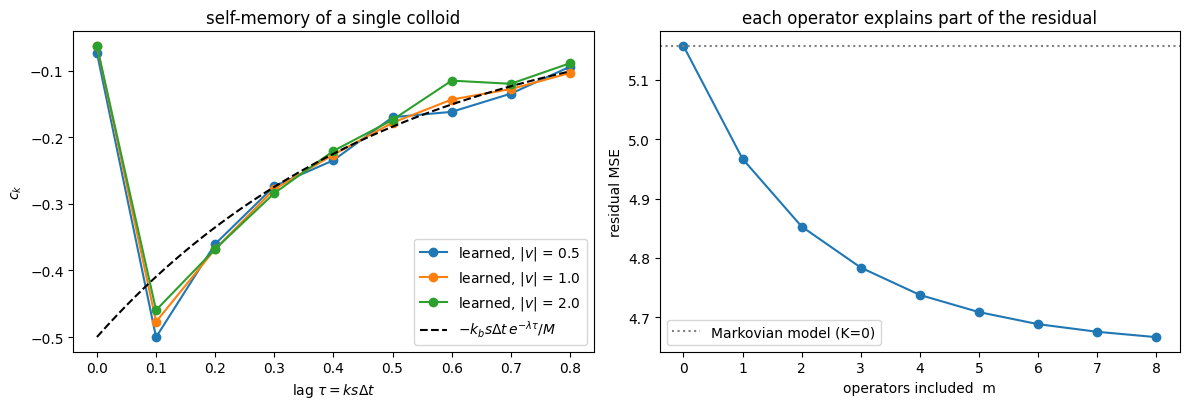

In [9]:
mz = models_A[KA]
x1 = torch.zeros(1, 1, 2, device=dev)
tau = np.arange(KA + 1) * sA * dtA
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
with torch.no_grad():
    for speed in [0.5, 1.0, 2.0]:
        v1 = torch.tensor([[[speed, 0.0]]], device=dev)
        ck = [op(x1, v1)[0, 0, 0].item() / speed for op in mz.ops]
        ax[0].plot(tau, ck, "o-", label=f"learned, $|v|$ = {speed}")
tt = np.linspace(0, tau[-1], 200)
ax[0].plot(tt, -A["k_b"] / A["M"] * sA * dtA * np.exp(-A["lam"] * tt), "k--", label=r"$-k_b s\Delta t\, e^{-\lambda\tau}/M$")
ax[0].set(xlabel=r"lag $\tau = k s \Delta t$", ylabel=r"$c_k$", title="self-memory of a single colloid"); ax[0].legend()

ax[1].plot(range(KA + 1), hists_A[KA], "o-")
ax[1].axhline(hists_A[0][0], color="gray", ls=":", label="Markovian model (K=0)")
ax[1].set(xlabel="operators included  m", ylabel="residual MSE", title="each operator explains part of the residual"); ax[1].legend()
plt.tight_layout(); plt.show()

The learned coefficients do not depend on $|\mathbf{v}|$ (the memory is linear, as the exact equation says) and
follow the exponential kernel $k_b e^{-\lambda\tau}$: <br>
**the network rediscovered the exact Mori–Zwanzig memory kernel from colloid trajectories alone.**

## A5. The orthogonal dynamics

The residual $\mathbf{W}^n = \mathbf{a}^n - \sum_k \boldsymbol\Omega^{(k)}(\cdot)$ is what the history of the colloids cannot predict.
Theory says its autocorrelation decays as $e^{-\lambda \tau}$. Let's check on the test trajectories.

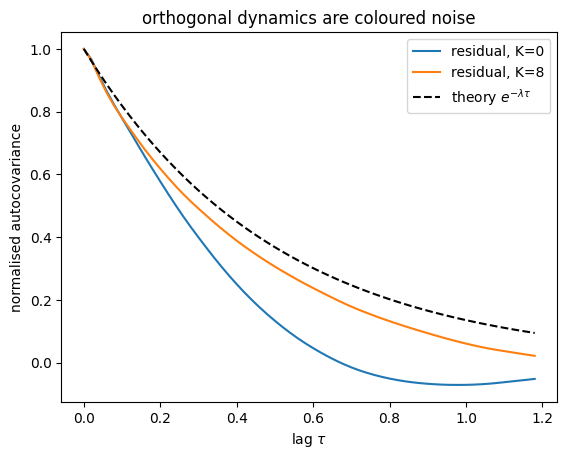

In [10]:
@torch.no_grad()
def residuals(model, X, V, dt):
    Xh, Vh, Y = make_dataset(X, V, dt, model.K, model.s)
    pred = torch.cat([model(Xh[i:i+1024].to(dev), Vh[i:i+1024].to(dev)).cpu() for i in range(0, len(Y), 1024)])
    return (Y - pred).reshape(X.shape[0], -1, X.shape[2], 2)       # (B, time, N, 2)

def autocov(R, maxlag):
    return np.array([(R[:, l:] * R[:, :R.shape[1] - l]).mean().item() for l in range(maxlag)])

RA = {K: residuals(models_A[K], XA_te, VA_te, dtA) for K in models_A}
lags = np.arange(60)
for K, R in RA.items():
    C = autocov(R, 60)
    plt.plot(lags * dtA, C / C[0], label=f"residual, K={K}")
plt.plot(lags * dtA, np.exp(-A["lam"] * lags * dtA), "k--", label=r"theory $e^{-\lambda\tau}$")
plt.xlabel(r"lag $\tau$"); plt.ylabel("normalised autocovariance"); plt.legend(); plt.title("orthogonal dynamics are coloured noise"); plt.show()

### Why we need them: deterministic rollouts cool down

So far, we have discarded the contribute of the orthogonal dynamic $\mathbf{W}^n$, thus we have considered deterministic models.  <br>
For this problem, the memory term is a **friction**: it removes energy, and in the true system the orthogonal dynamics put it back (fluctuation-dissipation).  <br>
Therefore if we ignore the orthogonal dynamics, the colloids will eventually stop.

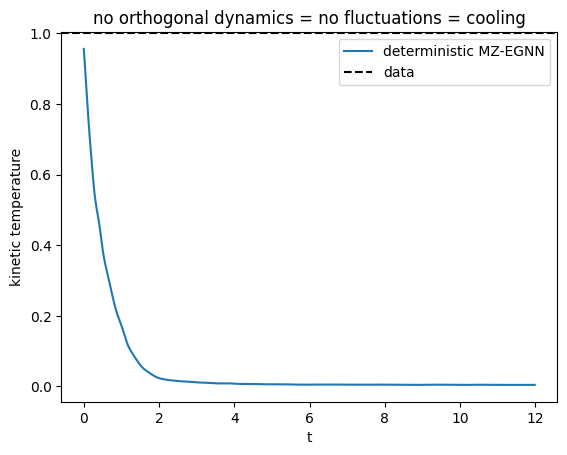

In [11]:
@torch.no_grad()
def rollout(model, X0, V0, steps, dt, L, noise=None):
    # X0, V0: (B, H, N, 2) true history (last index = present), H >= K*s+1.  noise = (sigma, phi) for AR(1) noise
    s, K = model.s, model.K
    Xs, Vs = list(X0.to(dev).unbind(1)), list(V0.to(dev).unbind(1))
    W = noise[0] * torch.randn_like(Vs[-1]) if noise is not None else None   # start from the stationary noise
    for _ in range(steps):
        a = model(torch.stack([Xs[-1 - k*s] for k in range(K + 1)], 1), torch.stack([Vs[-1 - k*s] for k in range(K + 1)], 1))
        if noise is not None:
            sig, phi = noise
            W = phi * W + math.sqrt(1 - phi ** 2) * sig * torch.randn_like(W)
            a = a + W
        v = Vs[-1] + dt * a
        Xs.append((Xs[-1] + dt * v) % L); Vs.append(v)
    return torch.stack(Xs, 1).cpu(), torch.stack(Vs, 1).cpu()

def start_histories(X, V, H, per_system=8, gap=200):
    # many independent starting points from the test trajectories
    ts = [H + i * gap for i in range(per_system)]
    return torch.cat([X[:, t-H:t] for t in ts]), torch.cat([V[:, t-H:t] for t in ts])

HA = KA * sA + 1
X0A, V0A = start_histories(XA_te, VA_te, HA)
_, Vdet = rollout(models_A[KA], X0A, V0A, 600, dtA, A["L"])
T_det = A["M"] * Vdet[:, HA:].pow(2).mean(dim=(0, 2, 3))
plt.plot(np.arange(600) * dtA, T_det, label="deterministic MZ-EGNN")
plt.axhline(A["T"], color="k", ls="--", label="data")
plt.xlabel("t"); plt.ylabel("kinetic temperature"); plt.legend(); plt.title("no orthogonal dynamics = no fluctuations = cooling"); plt.show()

### A stochastic closure constrained by fluctuation–dissipation

We model $\mathbf{W}^n$ as isotropic AR(1) noise (rotation-equivariant in distribution),
$\mathbf{W}^{n+1} = \phi\,\mathbf{W}^n + \sqrt{1-\phi^2}\,\sigma\,\boldsymbol\eta^n$, with:

- $\phi$ = lag-1 correlation of the residuals (for Part A, theory says $\phi = e^{-\lambda\Delta t}$);
- $\sigma$ **fixed by fluctuation–dissipation**: the noise amplitude must balance the learned friction at the data temperature. <br>
  Since $T \propto \sigma^2$, a few short rollouts with $\sigma \leftarrow \sigma\sqrt{T_{\rm data}/T_{\rm model}}$ are enough.
  We start from a small $\sigma$ (strong noise can push a learned model into states it never saw).

We apply exactly the same recipe to the Markovian model ($K=0$), so the comparison is fair.

In [12]:
def finite(Vr):
    # a learned model pushed far from the data can blow up: keep only rollouts that stayed finite
    ok = torch.isfinite(Vr).all(dim=(1, 2, 3))
    return Vr[ok], int((~ok).sum())

def calibrate_noise(model, X0, V0, dt, L, mass, T_target, phi, sig, iters=5, steps=400):
    for it in range(iters):
        torch.manual_seed(it)
        Vr, _ = finite(rollout(model, X0, V0, steps, dt, L, (sig, phi))[1])
        if len(Vr) == 0:
            sig /= 2; continue
        T = mass * Vr[:, X0.shape[1] + 100:].pow(2).mean().item()
        sig *= math.sqrt(T_target / T)
    return sig

def stochastic_comparison(models, R, X0, V0, dt, L, mass, T_data, steps=600):
    out = {}
    for K, m in models.items():
        C = autocov(R[K], 2)
        phi, sig0 = C[1] / C[0], 0.3 * math.sqrt(C[0])
        sig = calibrate_noise(m, X0, V0, dt, L, mass, T_data, phi, sig0)
        torch.manual_seed(123)
        Vr, n_bad = finite(rollout(m, X0, V0, steps, dt, L, (sig, phi))[1])
        out[K] = Vr[:, X0.shape[1]:]
        print(f"K={K}: phi = {phi:.3f}, calibrated sigma = {sig:.3f}, rollout temperature = {mass * out[K].pow(2).mean():.3f}"
              f"  ({n_bad}/{len(X0)} rollouts blew up and are discarded)")
    return out

T_data_A = A["M"] * VA_te.pow(2).mean().item()
print(f"data temperature {T_data_A:.3f};  theory phi = exp(-lambda dt) = {math.exp(-A['lam'] * dtA):.3f}")
rollA = stochastic_comparison(models_A, RA, X0A, V0A, dtA, A["L"], A["M"], T_data_A)

data temperature 0.981;  theory phi = exp(-lambda dt) = 0.961


K=0: phi = 0.966, calibrated sigma = 0.790, rollout temperature = 1.000  (0/32 rollouts blew up and are discarded)


K=8: phi = 0.964, calibrated sigma = 2.264, rollout temperature = 0.986  (0/32 rollouts blew up and are discarded)


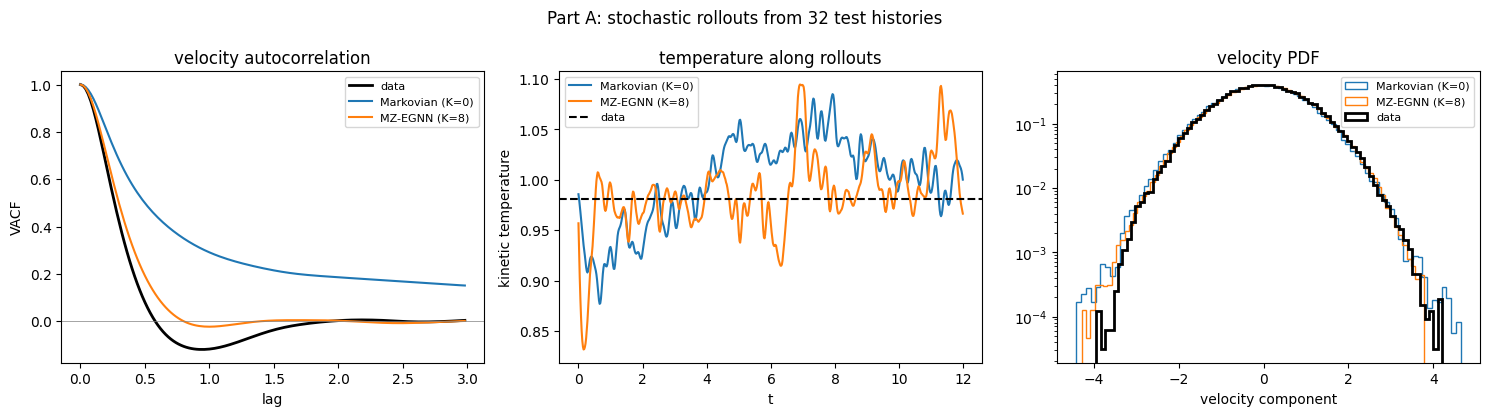

In [13]:
def plot_comparison(roll, V_true, dt, mass, maxlag, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
    lags = np.arange(maxlag) * dt
    ax[0].plot(lags, vacf(V_true, maxlag), "k", lw=2, label="data")
    for K, Vr in roll.items():
        name = "Markovian (K=0)" if K == 0 else f"MZ-EGNN (K={K})"
        ax[0].plot(lags, vacf(Vr[:, 100:], maxlag), label=name)
        ax[1].plot(np.arange(Vr.shape[1]) * dt, mass * Vr.pow(2).mean(dim=(0, 2, 3)), label=name)
        ax[2].hist(Vr[:, 100:].flatten().numpy(), bins=80, density=True, histtype="step", label=name)
    ax[1].axhline(mass * V_true.pow(2).mean(), color="k", ls="--", label="data")
    ax[2].hist(V_true.flatten().numpy(), bins=80, density=True, histtype="step", color="k", lw=2, label="data")
    ax[0].axhline(0, color="gray", lw=0.5)
    ax[0].set(xlabel="lag", ylabel="VACF", title="velocity autocorrelation")
    ax[1].set(xlabel="t", ylabel="kinetic temperature", title="temperature along rollouts")
    ax[2].set(xlabel="velocity component", yscale="log", title="velocity PDF")
    for a in ax: a.legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_comparison(rollA, VA_te, dtA, A["M"], 150, "Part A: stochastic rollouts from 32 test histories")

With the same noise recipe, both models reach the right temperature and velocity distribution, but only the model **with memory**
decorrelates at the right speed and develops the dip in the velocity autocorrelation. A Markovian closure cannot, no matter how its noise is tuned.

---
# Part B: heavy colloids in an explicit bath

## B1. The system

Now we consider a more complex system which cannot be solved analytically. A few **heavy colloids** (mass $M = 10$, diameter 1) move in a bath of many **light particles**
(mass 1, diameter 0.3). Everything interacts through the same soft repulsion and the dynamics is **Hamiltonian** (velocity Verlet,
energy conserving).

**We observe only the heavy colloids.** The bath is unresolved: it produces friction, memory (the bath has its own relaxation times,
backflow, caging), and fluctuations. There is no analytic kernel to compare with, but the recipe is unchanged.

In [14]:
Bp = dict(NH=6, NL=100, L=5.0, sH=1.0, sL=0.3, MH=10.0, mL=1.0, k_rep=100.0, T=1.0,
          dt_sim=2e-3, sub=25)
dtB = Bp["dt_sim"] * Bp["sub"]     # 0.05

def simulate_bath(B, n_samples, p=Bp, burn=4000):
    NH, NL, L = p["NH"], p["NL"], p["L"]
    sig = torch.cat([torch.full((NH,), p["sH"]), torch.full((NL,), p["sL"])]).to(dev)
    m = torch.cat([torch.full((NH,), p["MH"]), torch.full((NL,), p["mL"])]).to(dev)[None, :, None]
    x = init_positions(B, NH + NL, L, sig, p["k_rep"])
    v = torch.randn(B, NH + NL, 2, device=dev) * torch.sqrt(p["T"] / m)
    v = v - (m * v).sum(1, keepdim=True) / m.sum(1, keepdim=True)    # zero total momentum
    dt = p["dt_sim"]
    a = repulsion(x, L, sig, p["k_rep"]) / m
    X, V, XL = [], [], []
    for s in range(burn + n_samples * p["sub"]):
        v = v + 0.5 * dt * a
        x = (x + dt * v) % L
        a = repulsion(x, L, sig, p["k_rep"]) / m
        v = v + 0.5 * dt * a
        if s < burn // 2 and s % 100 == 0:        # rescale velocities during the first half of burn-in only
            v = v * torch.sqrt(p["T"] / (m * v ** 2).mean(dim=(1, 2), keepdim=True))
        if s >= burn and (s - burn) % p["sub"] == 0:
            X.append(x[:, :NH].clone()); V.append(v[:, :NH].clone())
            if len(XL) == 0: XL.append(x[:, NH:].clone())
    return torch.stack(X, 1).cpu(), torch.stack(V, 1).cpu(), XL[0].cpu()

t0 = time.time()
XB, VB, XB_light = simulate_bath(B=16, n_samples=1000)
print(f"simulated {XB.shape} in {time.time() - t0:.0f}s;  heavy-colloid temperature = {Bp['MH'] * VB.pow(2).mean():.3f}")

simulated torch.Size([16, 1000, 6, 2]) in 96s;  heavy-colloid temperature = 0.939


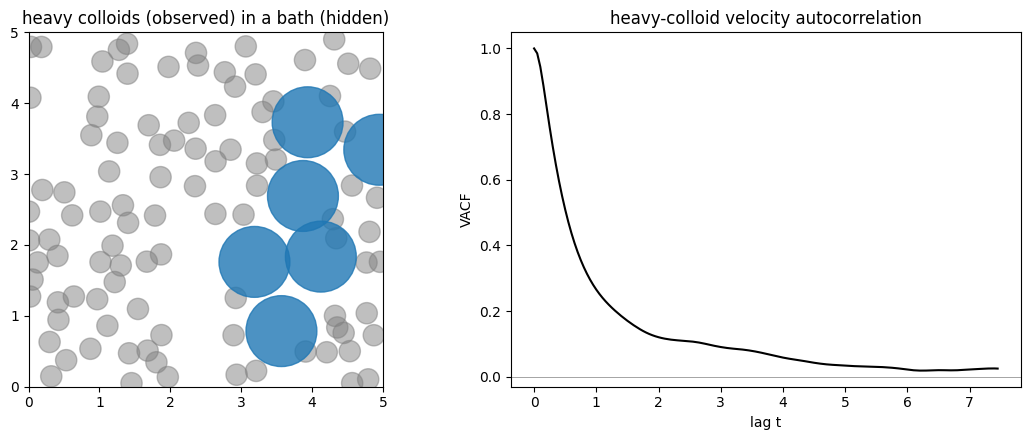

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for xl in XB_light[0]:
    ax[0].add_patch(plt.Circle(xl, Bp["sL"] / 2, color="gray", alpha=0.5))
for xh in XB[0, 0]:
    ax[0].add_patch(plt.Circle(xh, Bp["sH"] / 2, color="C0", alpha=0.8))
ax[0].set(xlim=(0, Bp["L"]), ylim=(0, Bp["L"]), aspect="equal", title="heavy colloids (observed) in a bath (hidden)")
ax[1].plot(np.arange(150) * dtB, vacf(VB, 150), "k")
ax[1].axhline(0, color="gray", lw=0.5)
ax[1].set(xlabel="lag t", ylabel="VACF", title="heavy-colloid velocity autocorrelation")
plt.tight_layout(); plt.show()

A fast initial decay (collisions with the bath) followed by a slow tail (the bath is pushed along and pushes back).

## B2. Train, look at the residuals, roll out

Same code as Part A. We use here a larger cutoff ($r_c = 2.5$).

In [16]:
sB, KB, rcB = 3, 8, 2.5
XB_tr, VB_tr, XB_te, VB_te = XB[:12], VB[:12], XB[12:], VB[12:]

models_B, hists_B = {}, {}
for K in [0, KB]:
    t0 = time.time()
    Xh, Vh, Y = make_dataset(XB_tr, VB_tr, dtB, K, sB)
    print(f"K = {K}  ({len(Y)} samples, <|a|^2>/2 = {Y.pow(2).mean():.4f})")
    torch.manual_seed(0)
    models_B[K], hists_B[K] = train_sequential(MZEGNN(K, sB, Bp["L"], rcB), Xh, Vh, Y)
    print(f"  trained in {time.time() - t0:.0f}s")

K = 0  (11988 samples, <|a|^2>/2 = 1.1282)


  Omega_0: residual MSE 1.0391
  trained in 16s
K = 8  (11700 samples, <|a|^2>/2 = 1.1267)


  Omega_0: residual MSE 1.0394


  Omega_1: residual MSE 0.9620


  Omega_2: residual MSE 0.9585


...

  Omega_4: residual MSE 0.9554


  Omega_5: residual MSE 0.9548


  Omega_6: residual MSE 0.9540


  Omega_7: residual MSE 0.9529


  Omega_8: residual MSE 0.9522
  trained in 291s


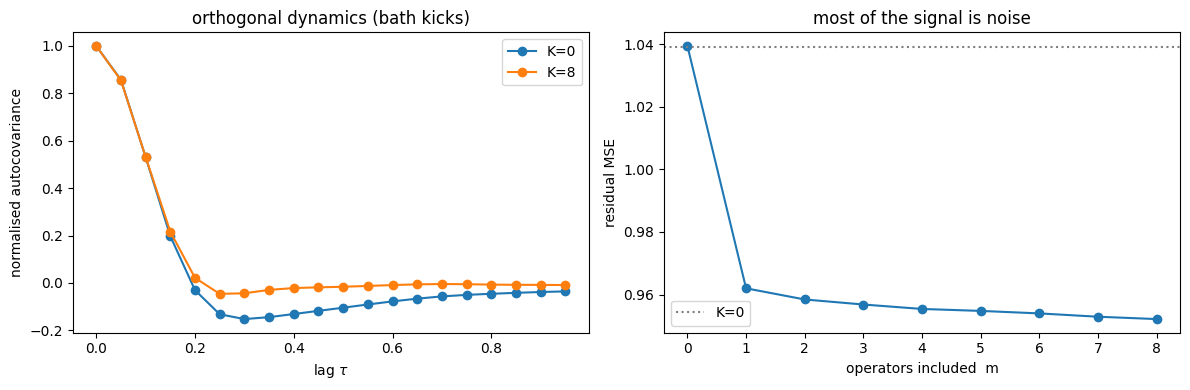

In [17]:
RB = {K: residuals(models_B[K], XB_te, VB_te, dtB) for K in models_B}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for K, R in RB.items():
    C = autocov(R, 20)
    ax[0].plot(np.arange(20) * dtB, C / C[0], "o-", label=f"K={K}")
ax[0].set(xlabel=r"lag $\tau$", ylabel="normalised autocovariance", title="orthogonal dynamics (bath kicks)"); ax[0].legend()
ax[1].plot(range(KB + 1), hists_B[KB], "o-"); ax[1].axhline(hists_B[0][0], color="gray", ls=":", label="K=0")
ax[1].set(xlabel="operators included  m", ylabel="residual MSE", title="most of the signal is noise"); ax[1].legend()
plt.tight_layout(); plt.show()

Here the orthogonal dynamics dominate: the bath kicks are most of the acceleration signal, and memory only explains a modest fraction
of the variance. Yet that fraction is what shapes the long-time behaviour, as the rollouts show.

data temperature 0.992


K=0: phi = 0.857, calibrated sigma = 0.325, rollout temperature = 1.003  (0/32 rollouts blew up and are discarded)


K=8: phi = 0.855, calibrated sigma = 0.616, rollout temperature = 0.998  (0/32 rollouts blew up and are discarded)


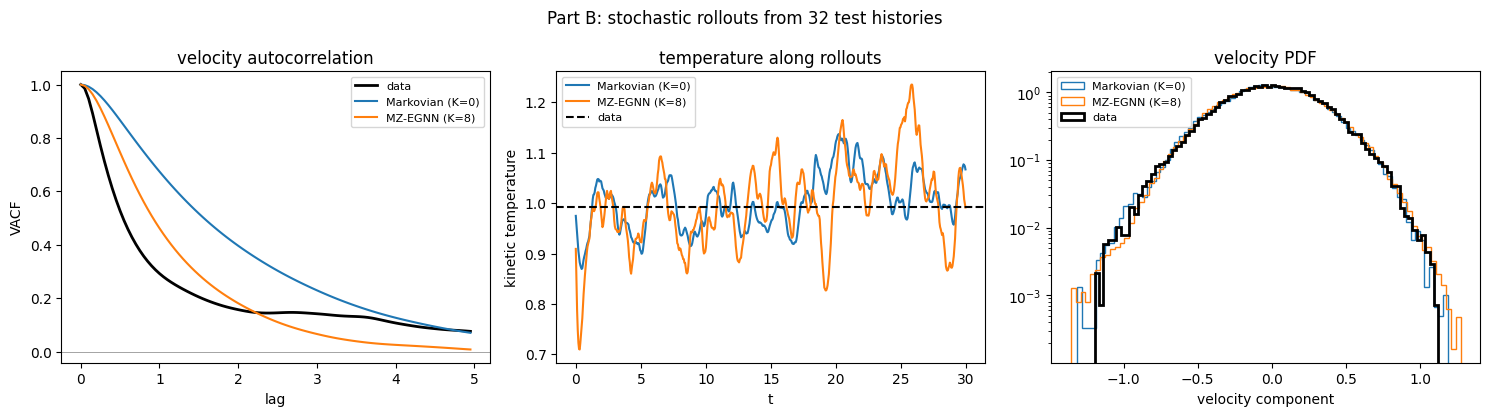

In [18]:
HB = KB * sB + 1
X0B, V0B = start_histories(XB_te, VB_te, HB, per_system=8, gap=100)
T_data_B = Bp["MH"] * VB_te.pow(2).mean().item()
print(f"data temperature {T_data_B:.3f}")
rollB = stochastic_comparison(models_B, RB, X0B, V0B, dtB, Bp["L"], Bp["MH"], T_data_B)
plot_comparison(rollB, VB_te, dtB, Bp["MH"], 100, "Part B: stochastic rollouts from 32 test histories")

Again both models are at the right temperature with the right velocity PDF, and again the Markovian model decorrelates far too slowly.
The MZ-EGNN captures the fast initial decay, but not the slow tail beyond $t \approx 2$: our memory window is only
$K s \Delta t = 8 \times 3 \times 0.05 = 1.2$. Can longer memory (e.g. larger $K$, or log-spaced lags) help improving?

## Exercises

1. **Scale separation.** In Part A increase $\lambda$ (fast bead, e.g. $\lambda = 20$, with $D = \lambda T / k_b$). When does the Markovian model become good enough?
2. **Memory depth.** Sweep $K$ and the stride $s$ in Part A. Which total memory window $K s \Delta t$ is needed, compared with $1/\lambda$?
3. **Symmetry matters.** Remove the self term $a\,\mathbf{v}_i$ (a Galilean-invariant model). What happens to the learned kernel and the rollouts?
4. **No symmetry.** Replace the EGNN operators with an MLP acting on absolute positions and velocities of all particles. Compare the data needed and the rotation error.
5. **Unrolled training.** Train with an $R$-step rollout loss and check whether long rollouts become more stable.
6. **Non-local memory (advanced).** Couple the beads of neighbouring colloids with springs. Now the memory of colloid $i$ depends on the history of its neighbours: the memory operators need the graph too.
7. **Mass ratio (Part B).** Make the colloids heavier ($M = 50$). What happens to the memory and to the relative size of the orthogonal dynamics?